In [101]:
import numpy as np
import scipy.ndimage as ndimage
from scipy.optimize import curve_fit

import matplotlib
from matplotlib import pyplot as plt

from PyAstronomy import pyasl
import pyphot
from pyphot import (unit, Filter)
from reproject import reproject_exact, reproject_adaptive, reproject_interp, reproject_from_healpix

from astropy.io import (fits, ascii)
from astropy import wcs
import astropy.units as u
from astropy.visualization import SqrtStretch, PercentileInterval

# from photutils import aperture_photometry, RectangularAperture
# from photutils import ApertureStats

from astropy.table import Table

import os
import csv
import glob

import warnings
warnings.filterwarnings("ignore")

In [38]:
data_dir= 'data/GTC-OSIRIS/Sci_spec/combined_grism/'
filt_dir = 'data/Filter/'

# Funcs

In [39]:
## filters 
def filter_(ZTF_band):
    
    if ZTF_band  ==  'g':
        
        filcont  = ascii.read(filt_dir+'Palomar_ZTF.g.dat')
        wave     = np.array(filcont['col1'])*unit['AA']
        transmit = np.array(filcont['col2'])
        _filter  = Filter(wave, transmit, name='ZTF_g', dtype='energy', unit='Angstrom')
        
    if ZTF_band  ==  'r':

        filcont  = ascii.read(filt_dir+'Palomar_ZTF.r.dat') 
        wave     = np.array(filcont['col1'])*unit['AA']
        transmit = np.array(filcont['col2'])
        _filter  = Filter(wave, transmit, name='ZTF_r', dtype='energy', unit='Angstrom')
        
    return _filter

In [40]:
def flambda2fnu(flambda, band):
    
    if band == 'g':
        lambda_eff = 4722.74  # AA
    if band == 'r':
        lambda_eff = 6339.61  # AA
        
    fnu = 3.34*1e4*lambda_eff**2*flambda
    
    return fnu

In [41]:
def fnu2mag(fnu, band):
    
    if band == 'g':
        F_nu0 = 3963.97  ##Jy
    if band == 'r':
        F_nu0 = 3042.00  ##Jy
        
    mag = -2.5*np.log10(fnu/F_nu0)
    
    return mag

In [67]:
def mag2fnu(mag, band):
    
    if band == 'g':
        F_nu0 = 3963.97  ##Jy
    if band == 'r':
        F_nu0 = 3042.00  ##Jy
        
    F_nu = F_nu0 * 10**(-mag/2.5)
    
    return F_nu

In [52]:
def mag_GTC(objname):
    
    spec_path = glob.glob(data_dir+'*'+objname+'*.fits')[0]
    gtc_spec = fits.open(spec_path)
    wave_spec = gtc_spec[1].data["wave"]
    flux_spec = gtc_spec[1].data["flux"]*1e-17
    MJD = gtc_spec[0].header["MJD"]
    
    # spectra coevolve filters, obtain flux
    filter_ZTFr = filter_('r')
    filter_ZTFg = filter_('g')
    wv = wave_spec*unit['AA']
    fl = flux_spec*unit['erg/s/cm**2/AA']
    flux_ZTFr  = filter_ZTFr.get_flux(wv, fl) #erg/s/cm**2/AA
    flux_ZTFg  = filter_ZTFg.get_flux(wv, fl) #erg/s/cm**2/AA
    
    # convert flux to Jy and mag
    fnu_ZTFg = flambda2fnu(flux_ZTFg, 'g')
    fnu_ZTFr = flambda2fnu(flux_ZTFr, 'r')
    mag_ZTFg = fnu2mag(fnu_ZTFg, 'g')
    mag_ZTFr = fnu2mag(fnu_ZTFr, 'r')
    
    return [MJD, fnu_ZTFg, fnu_ZTFr]

In [70]:
def mag_ZTF(objname, MJD):
    lc_df_ = ascii.read(glob.glob("data/lc/"+objname+"*.dat")[0])
    
    ### r band
    t_r = lc_df_["MJD"][lc_df_["band"] == 'r']
    rmag_ = lc_df_["mag"][lc_df_["band"] == 'r']
    rmag_err = lc_df_["magerr"][lc_df_["band"] == 'r']

    ### g band
    t_g = lc_df_["MJD"][lc_df_["band"] == 'g']
    gmag_ = lc_df_["mag"][lc_df_["band"] == 'g']
    gmag_err = lc_df_["magerr"][lc_df_["band"] == 'g']
    
    ## select 
    spec_epoch = MJD
    
    phot_time_g = np.where(np.abs(t_g-spec_epoch) < 10)
    phot_mag_ZTFg = np.nanmedian(gmag_[phot_time_g])
    phot_magerr_ZTFg = np.nanmedian(gmag_err[phot_time_g])
    Fnu_ZTFg = mag2fnu(phot_mag_ZTFg, 'g')

    phot_time_r = np.where(np.abs(t_r-spec_epoch) < 10)
    phot_mag_ZTFr = np.nanmedian(rmag_[phot_time_r])
    phot_magerr_ZTFr = np.nanmedian(rmag_err[phot_time_r])
    Fnu_ZTFr = mag2fnu(phot_mag_ZTFr, 'r')
    
    
    return [Fnu_ZTFg, Fnu_ZTFr]

In [79]:
def compare_(objname, _plot=True):
    
    mag_GTC_ = mag_GTC(objname)
    mag_ZTF_ = mag_ZTF(objname, mag_GTC_[0])
    
    if _plot:
        fig = plt.figure(figsize=(6,4.5))
        plt.rcParams["xtick.direction"] = "in"
        plt.rcParams["ytick.direction"] = "in"
        plt.rcParams["xtick.top"] = True
        plt.rcParams["ytick.right"] = True
        plt.rcParams["xtick.minor.visible"] = True
        plt.rcParams["ytick.minor.visible"] = True
        plt.rcParams["xtick.labelsize"] = 14
        plt.rcParams["ytick.labelsize"] = 14

        ax = fig.add_subplot(111)
        # ax.set_ylim(-1.5,1.5)
        ax.set_xlim(4600, 6500)
        ax.set_ylabel(r"$\rm F_{\nu, GTC} / F_{\nu, ZTF} $", fontsize = 16)
        ax.set_xlabel(r"$\rm Wavelength$", fontsize = 16)
        ax.set_title(objname, fontsize = 15)
        
        lambda_eff_ZTFr = 6339.61  # AA
        lambda_eff_ZTFg = 4722.74  # AA
        mag_ZTFg, mag_ZTFr = mag_GTC_[1], mag_GTC_[2]
        phot_mag_ZTFg, phot_mag_ZTFr = mag_ZTF_[0], mag_ZTF_[1]
        flux_ratio_g = mag_ZTFg/phot_mag_ZTFg
        flux_ratio_r = mag_ZTFr/phot_mag_ZTFr
        
        ax.scatter(lambda_eff_ZTFg, mag_ZTFg/phot_mag_ZTFg, c='C2', label="g")
        ax.scatter(lambda_eff_ZTFr, mag_ZTFr/phot_mag_ZTFr, c='C3', label="r")

        ax.hlines(1.0, xmin=4600, xmax=6500, color='k', ls='--')
        ax.fill_between([4600,6500], 1.25, 0.75, color='grey', alpha=0.3, edgecolors='none')
        
    return [flux_ratio_g, flux_ratio_r]

# Results


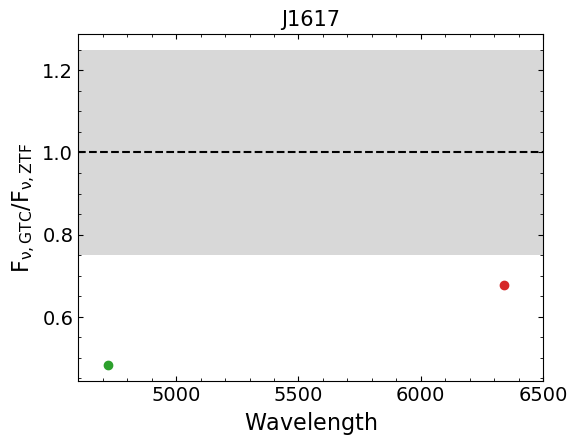

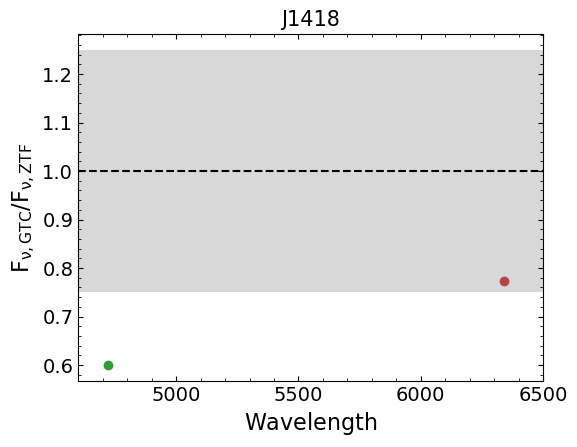

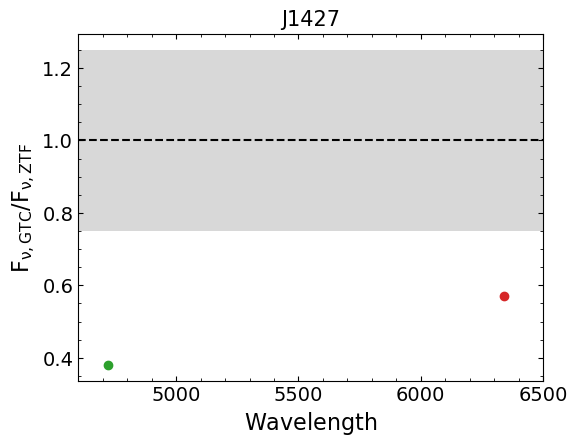

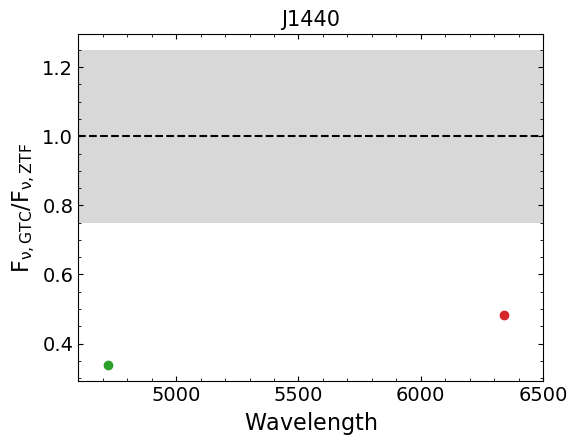

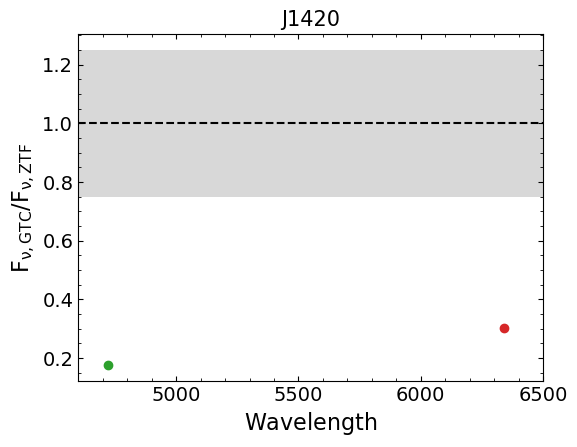

...

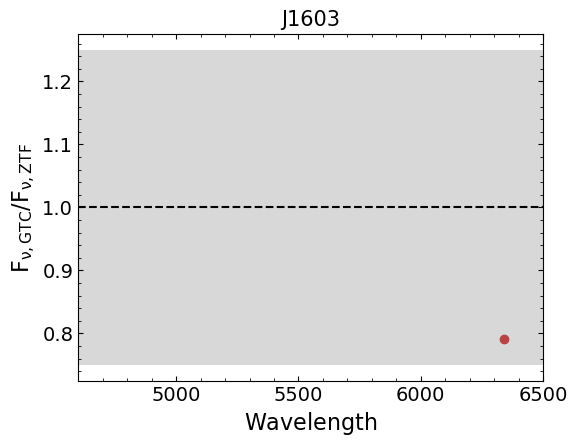

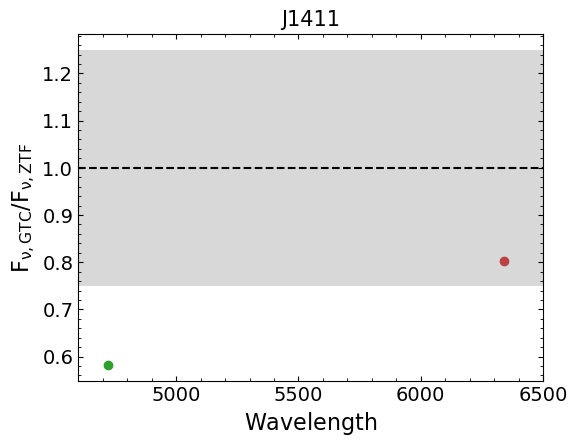

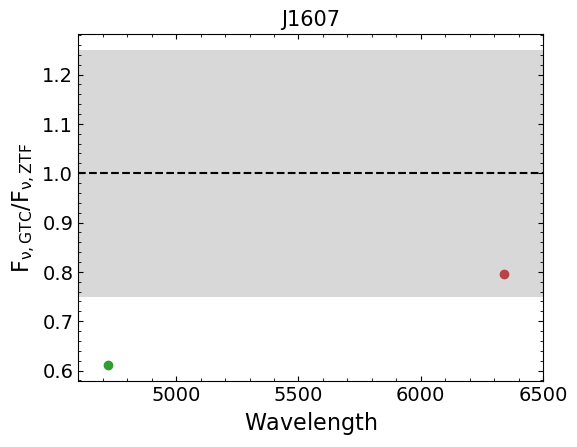

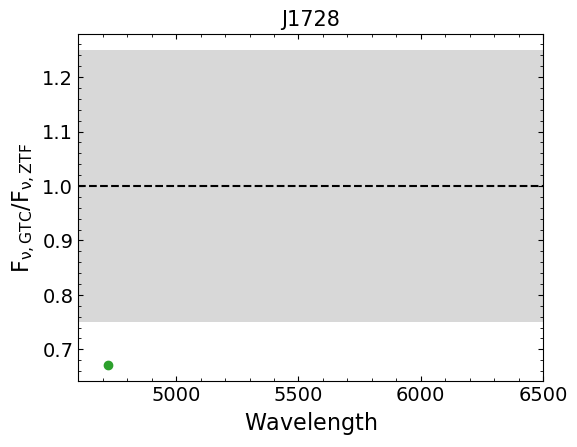

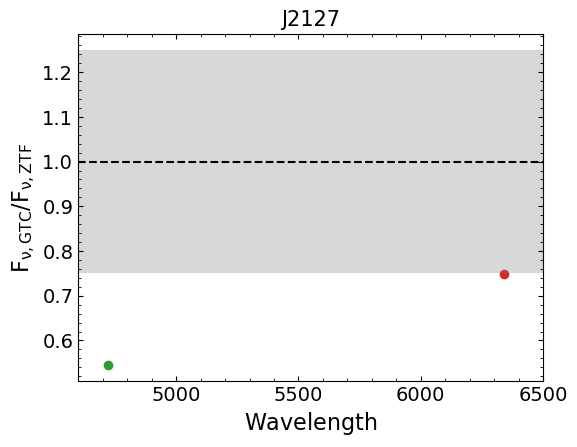

In [80]:
df = ascii.read('data/target_info.dat')
objname_l = df['Object']
FR_g = []
FR_r = []
for objname in objname_l:
    fr = compare_(objname)
    FR_g.append(fr[0])
    FR_r.append(fr[1])

In [87]:
scale_factor = []
for i in range(len(FR_g)):
    fr_g, fr_r = FR_g[i], FR_r[i]
    if np.isnan(fr_g):
        scale_factor.append(fr_r)
    elif np.isnan(fr_r):
        scale_factor.append(fr_g)
    else:
        scale_factor.append(0.5*(fr_g+fr_r)) 

In [88]:
scale_factor

[0.5796614594226002,
 0.6864808238952507,
 0.47557257368189865,
 0.410533130053616,
 0.24004006986116344,
 0.4313840324819326,
 0.7906200341026766,
 0.6923842403254229,
 0.7038595991063341,
 0.6714540200253768,
 0.6475238290588405]

In [ ]:
spec_path = glob.glob(data_dir+'*'+objname+'*.fits')[0]
gtc_spec = fits.open(spec_path)
wave_spec = gtc_spec[1].data["wave"]
flux_spec = gtc_spec[1].data["flux"]

In [98]:
save_path = 'data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/'

In [102]:
flux_cal_li = []
for i in range(len(objname_l)):
    objname = objname_l[i]
    spec_path = glob.glob(data_dir+'*'+objname+'*.fits')[0]
    gtc_spec = fits.open(spec_path)
    wave_spec = gtc_spec[1].data["wave"]
    flux_spec = gtc_spec[1].data["flux"]
    
    F_scale = scale_factor[i]
    flux_cal = flux_spec/F_scale
    
    df = Table()
    df["fluxCal"] = flux_cal
    ascii.write(df,save_path+objname+"_FluxCal.dat",overwrite=True)

# multiprocessing

In [ ]:
import pkg.create_broadband
import multiprocessing as mp

single_files = glob.glob(data_dir+'*'+objname+'*.fits')

def create_broad_band(i):    
    i = int(i)
    file = single_files[i]
    create_broadband.create_broadband(file,survey,save_dir,band='2')
    print(file)
    return 

In [12]:
input_para = np.arange(len(single_files)).reshape(len(single_files),-1)
pool    = mp.Pool(processes=20)
result  = pool.map(create_broad_band,input_para)

/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/1_MUSE-pipline/ESO115-G021/single_observation/wcs_calib/ESO115-G02_DATACUBE_FINAL_2019-10-10T08:40:34.172.fits
/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/1_MUSE-pipline/ESO115-G021/single_observation/wcs_calib/ESO115-G02_DATACUBE_FINAL_2019-10-11T08:21:02.558.fits
/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/1_MUSE-pipline/ESO115-G021/single_observation/wcs_calib/ESO115-G02_DATACUBE_FINAL_2019-10-02T05:43:47.672.fits
/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/1_MUSE-pipline/ESO115-G021/single_observation/wcs_calib/ESO115-G02_DATACUBE_FINAL_2019-10-16T03:43:26.048.fits


# compare the single observations

In [6]:
import compare_observation

In [7]:
phot_aper_dir = img_dir+objname+'/'+survey+'/single_observation/'
spec_aper_dir = data_dir+objname+'/'

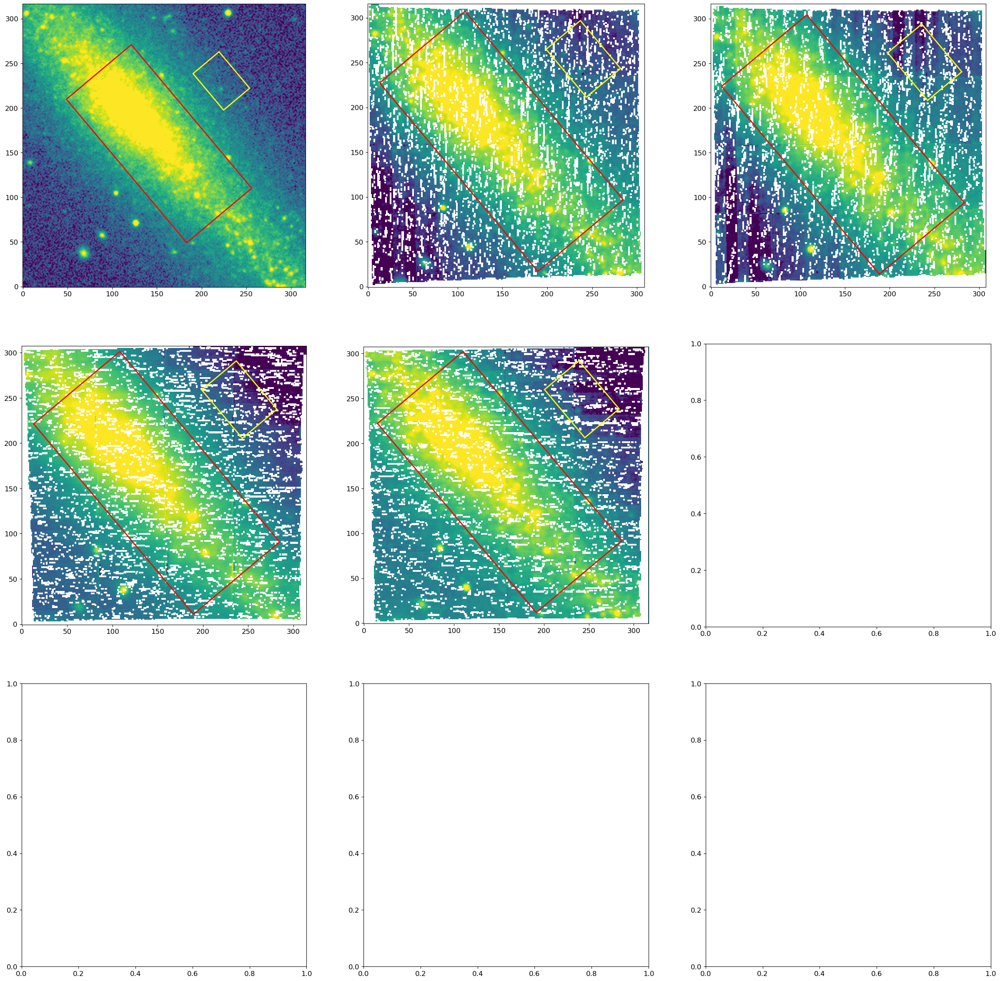

In [18]:
band     = 'i'
compare_observation.check_phot_aperture(objname,survey,phot_aper_dir,band)

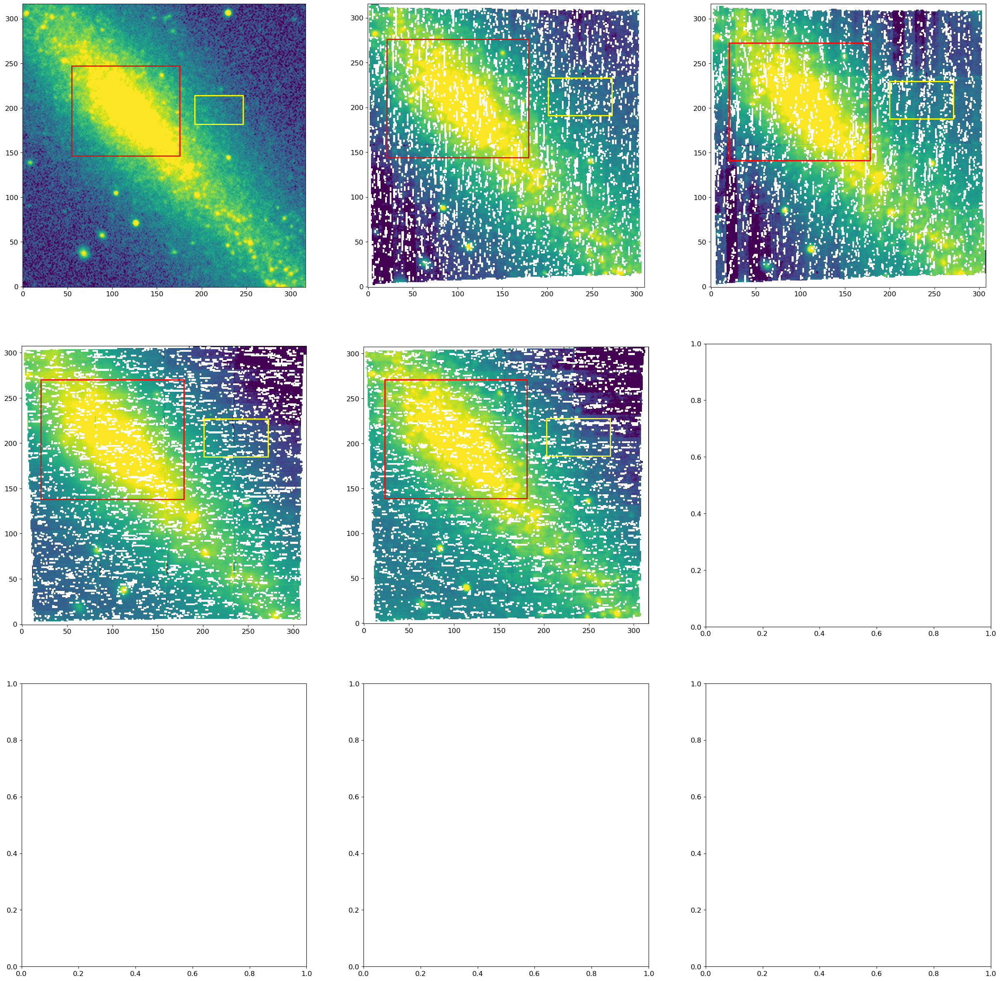

In [19]:
band     = 'i'
compare_observation.check_phot_aperture(objname,survey,spec_aper_dir,band)

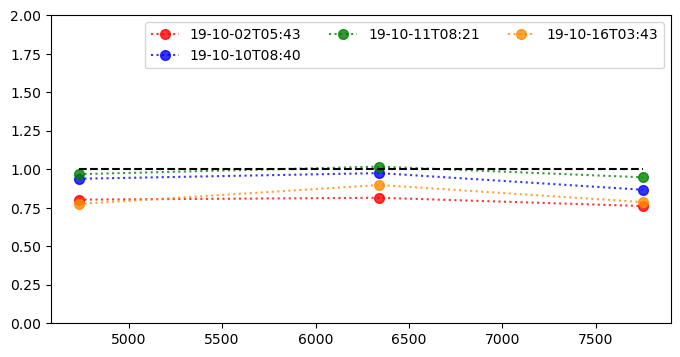

In [20]:
spec_dir = data_dir+objname+'/single_observation/wcs_calib/'
file_dir = img_dir+objname+'/'+survey+'/single_observation/'
compare_observation.compare_photometry(survey,objname,phot_aper_dir,spec_dir,file_dir)

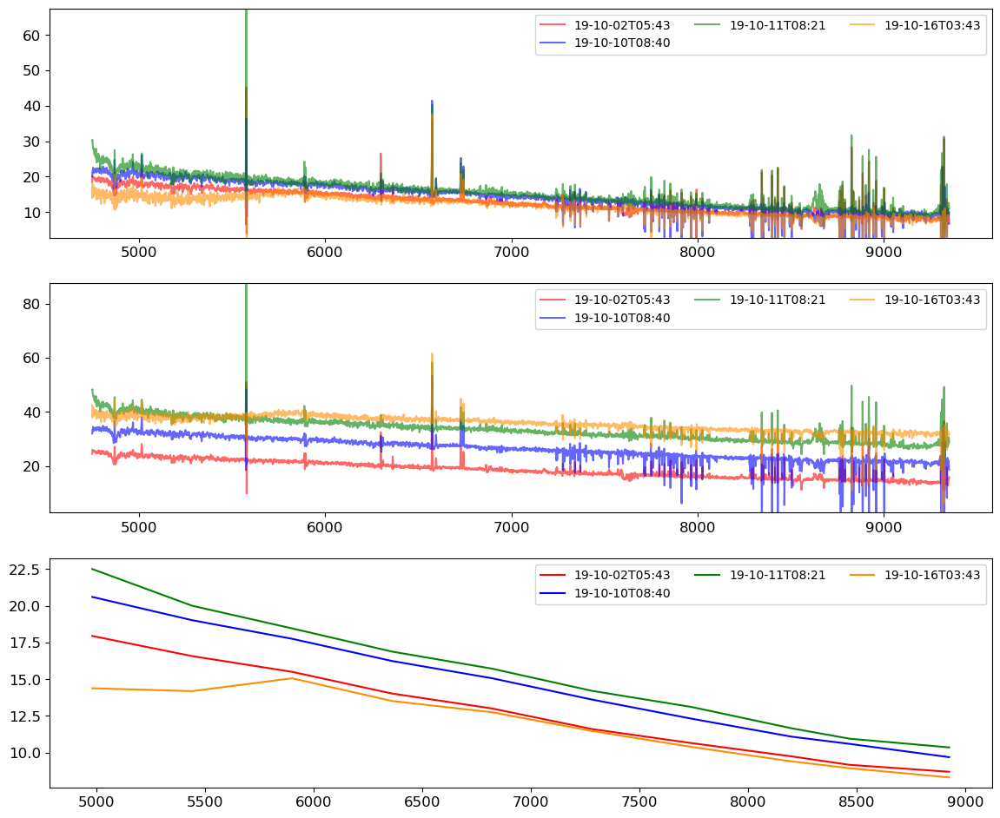

In [21]:
spec_aper_dir = data_dir+objname+'/'
compare_observation.compare_spec(spec_dir,spec_aper_dir)

In [8]:
refdate = '19-10-11T08:21'
det_date= None

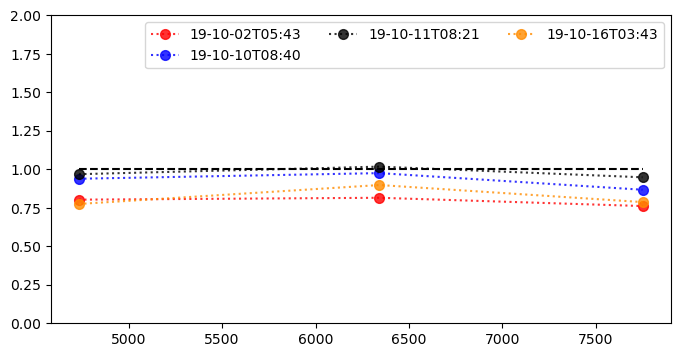

In [23]:
compare_observation.compare_photometry(survey,objname,phot_aper_dir,spec_dir,file_dir,\
                                       refdate=refdate,det_date=det_date)


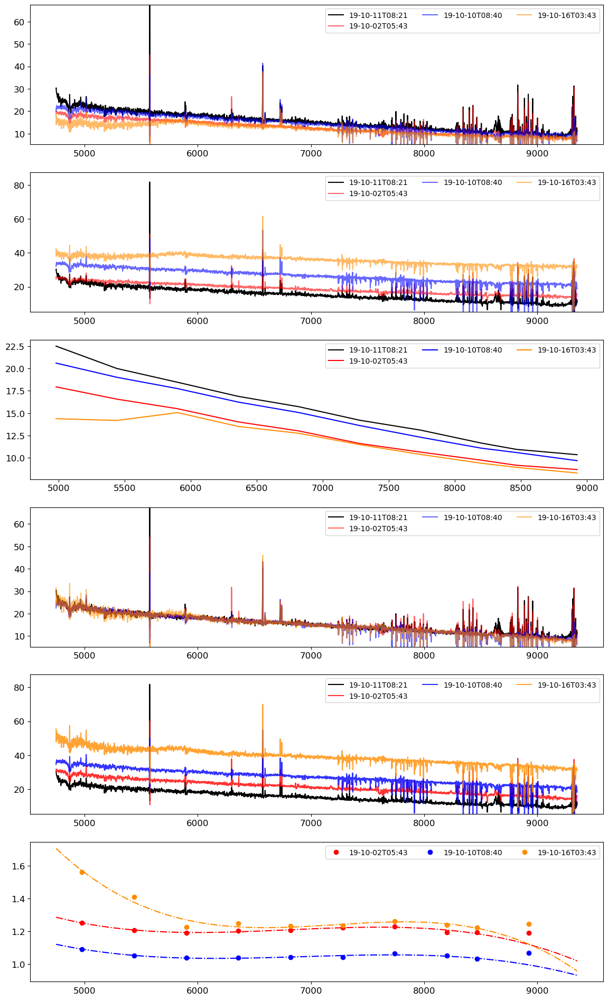

In [24]:
compare_observation.compare_spec(spec_dir,spec_aper_dir,refdate=refdate,det_date=det_date)

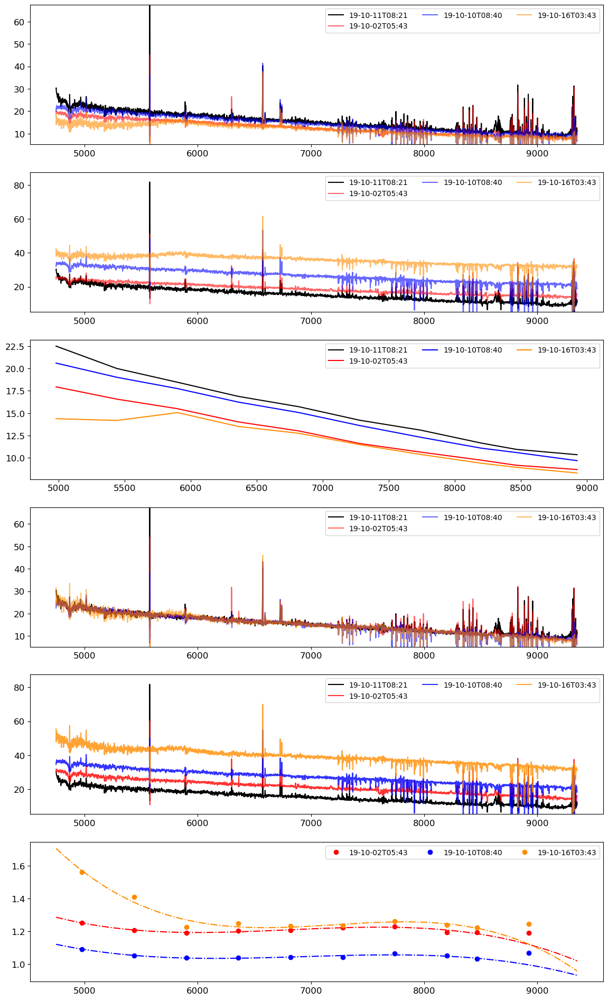

In [25]:
save_dir = '/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/single_observation/'
compare_observation.compare_spec(spec_dir,spec_aper_dir,refdate=refdate,det_date=det_date,save_dir=save_dir)

In [26]:
if not os.path.exists(img_dir+objname+'/'+survey+'/single_observation/calib_flux'):
    os.mkdir(img_dir+objname+'/'+survey+'/single_observation/calib_flux')

In [27]:
import create_broadband
import multiprocessing as mp

save_dir = img_dir+objname+'/'+survey+'/single_observation/calib_flux/'
single_files = glob.glob('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/single_observation/*')

def create_broad_band(i):    
    i = int(i)
    file = single_files[i]
    create_broadband.create_broadband(file,survey,save_dir,band='all')
    print(file)
    return 

In [28]:
input_para = np.arange(len(single_files)).reshape(len(single_files),-1)
pool    = mp.Pool(processes=20)
result  = pool.map(create_broad_band,input_para)

/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/ESO115-G021/single_observation/ESO115-G02_DATACUBE_FINAL_2019-10-16T03:43:26.048.fits
/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/ESO115-G021/single_observation/ESO115-G02_DATACUBE_FINAL_2019-10-02T05:43:47.672.fits
/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/ESO115-G021/single_observation/ESO115-G02_DATACUBE_FINAL_2019-10-11T08:21:02.558.fits
/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/ESO115-G021/single_observation/ESO115-G02_DATACUBE_FINAL_2019-10-10T08:40:34.172.fits


IndexError: list index out of range

In [9]:
new_phot_dir = img_dir+objname+'/'+survey+'/single_observation/calib_flux/'
new_spec_dir = '/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/single_observation/'

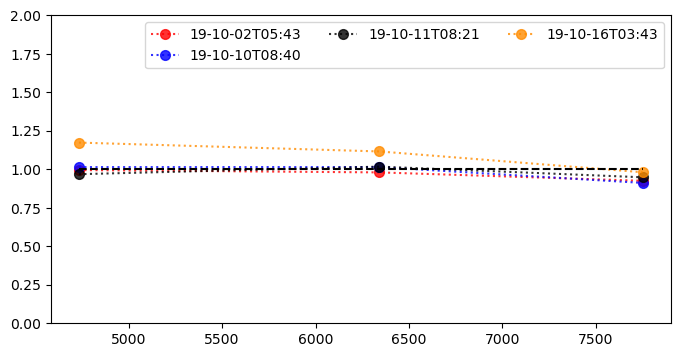

In [12]:
compare_observation.compare_photometry(survey,objname,phot_aper_dir,new_spec_dir,new_phot_dir,\
                                       refdate=refdate,det_date=[det_date])

In [29]:
new_phot_dir = img_dir+objname+'/'+survey+'/single_observation/calib_flux/'
new_spec_dir = '/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/single_observation/'

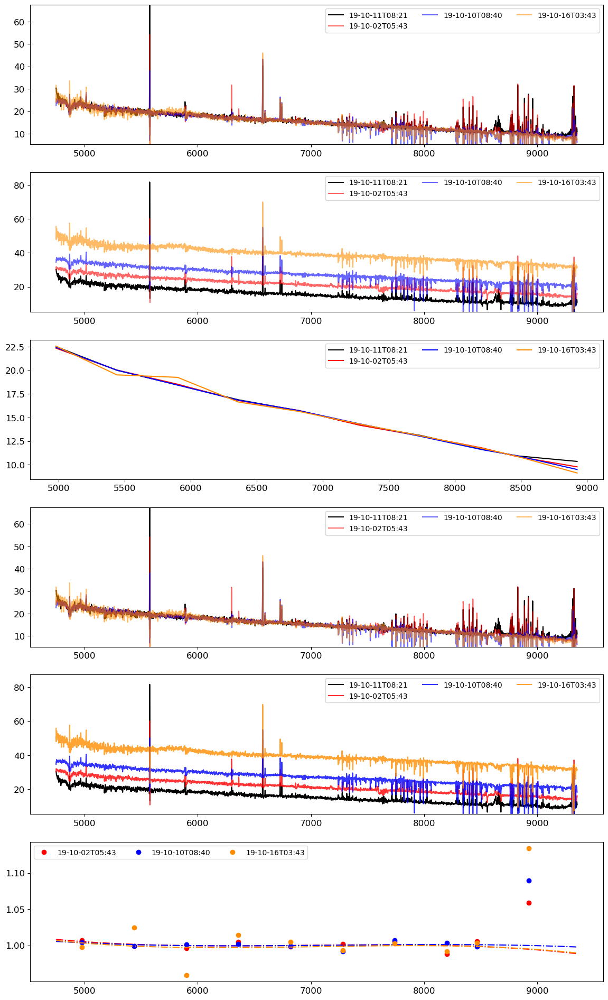

In [30]:
compare_observation.compare_spec(new_spec_dir,spec_aper_dir,refdate=refdate)

In [37]:
import multiprocessing as mp
import shutil

raw_spec_file_dir = glob.glob('/media/yong-group/DGIS1/MUSE/MUSE_reduced_YXL/'+objname.split('-')[0]+'*/reflex_end_products/*/')[1]
new_spec_dir = '/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/single_observation/'
new_spec_file = glob.glob('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/single_observation/*')

if not os.path.exists('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/wcs_pipeline'):
    os.mkdir('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/pipeline')
    os.mkdir('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/pipeline/data')
    os.mkdir('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/pipeline/reduced')
    
pipe_dir = '/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/pipeline/data/'

def create_pipeline(spec_file):
    spec_file = spec_file[0]
    file_name = spec_file.split('observation/')[1]
    file_date = file_name.split('FINAL_')[1]
    if not os.path.exists(pipe_dir+'MUSE.'+file_date):
        os.mkdir(pipe_dir+'MUSE.'+file_date)
        
    save_dir  = pipe_dir+'MUSE.'+file_date+'/'
    raw_spec_files = raw_spec_file_dir+'MUSE.'+file_date[:-8]
    pre_spec_dir   = data_dir+objname+'/single_observation/wcs_calib/'
    
    pix_table = glob.glob(raw_spec_files+'*.fits/*PIXTABLE*')[0]
    
    white_img = glob.glob(pre_spec_dir+'*IMAGE*'+file_date)[0]

    if not glob.glob(save_dir+'*PIX*'):
        shutil.copy(pix_table,save_dir)                
    if not glob.glob(save_dir+'*IMAGE*'):    
        shutil.copy(white_img,save_dir)
    if not glob.glob(save_dir+'*DATACUBE*'):
        shutil.copy(spec_file,save_dir)  
    return

In [38]:
input_para = np.array(new_spec_file).reshape(len(new_spec_file),-1)

In [39]:
pool    = mp.Pool(processes=20)
result  = pool.map(create_pipeline,input_para)

In [6]:
import create_broadband
if not os.path.exists(img_dir+objname+'/'+survey+'/fluxcal_synthetic'):
    os.mkdir(img_dir+objname+'/'+survey+'/fluxcal_synthetic')
    
save_dir = img_dir+objname+'/'+survey+'/fluxcal_synthetic/'
combine_file = glob.glob('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/*DATACUBE*')[0]
create_broadband.create_broadband(combine_file,survey,save_dir,band='all')


In [7]:
if not os.path.exists(img_dir+objname+'/'+survey+'/synthetic'):
    os.mkdir(img_dir+objname+'/'+survey+'/synthetic')

save_dir = img_dir+objname+'/'+survey+'/synthetic/'
pre_combine_file = glob.glob(data_dir+objname+'/*DATACUBE*')[0]
create_broadband.create_broadband(pre_combine_file,survey,save_dir,band='all')

In [8]:
import compare_observation

In [9]:
phot_aper_dir = img_dir+objname+'/'+survey+'/single_observation/'
band = 'i'
file = glob.glob(img_dir+objname+'/'+survey+'/fluxcal_synthetic/*_'+band+'*')[0]


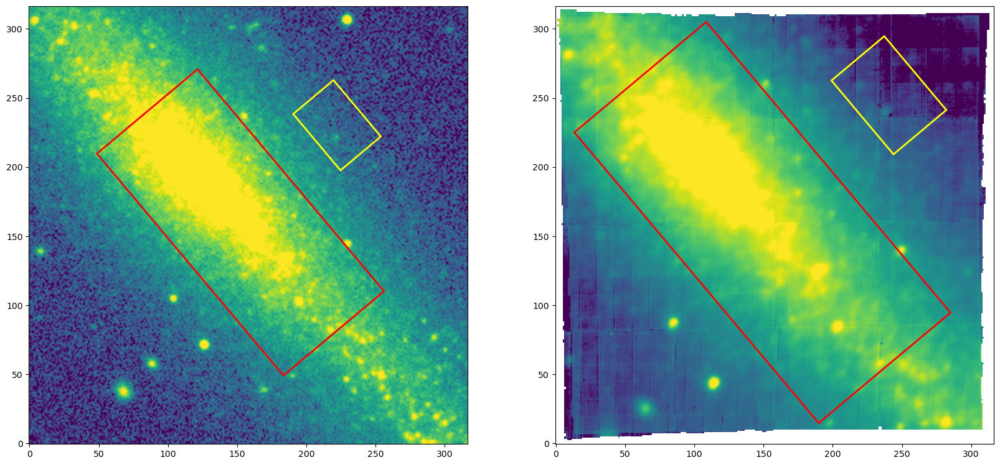

In [10]:
compare_observation.check_phot_aperture_single(objname,file,survey,phot_aper_dir,band)

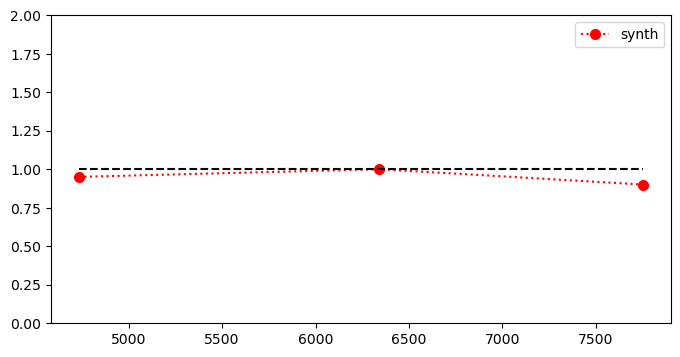

array([0.95068031, 1.00047676, 0.90111265])

In [19]:
compare_observation.compare_photometry_synth(survey,objname,phot_aper_dir,img_dir+objname+'/'+survey+'/synthetic')

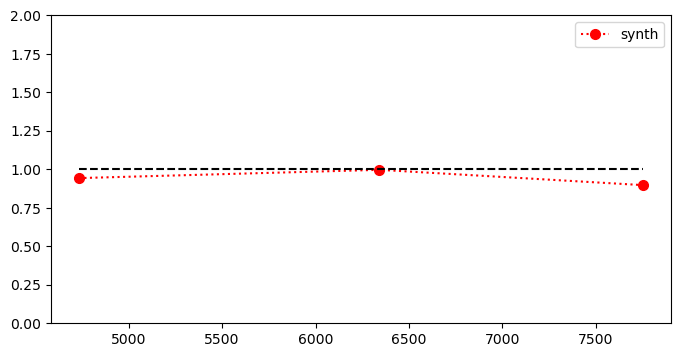

In [13]:
ratio = compare_observation.compare_photometry_synth(survey,objname,phot_aper_dir,img_dir+objname+'/'+survey+'/fluxcal_synthetic')

In [15]:
ratio,np.median(ratio)

(array([0.94272539, 0.99642659, 0.89729818]), 0.9427253892303534)

In [16]:
import shutil

In [32]:
if not os.path.exists('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/product/'+objname):
    os.mkdir('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/product/'+objname)
    
final_dir = '/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/product/'+objname+'/'

combine_fit =  glob.glob('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/*DATACUBE*')[0]
combine_img =  glob.glob('/media/yong-group/DGIS1/MUSE/MUSE_reduced_LX/3_MUSE-fluxcal/'+objname+'/*(white)*')[0]
if not glob.glob(final_dir+'*DATACUBE*'):
    shutil.copy(combine_fit,final_dir)
    shutil.copy(combine_img,final_dir)